# Load soil moisture data #

In [9]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, models, expts
from cdrmip_extremes import load_esgf, utils, load_data

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/43569/status,
Dashboard: /proxy/43569/status,Workers: 28
Total threads: 28,Total memory: 0 B
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40613,Workers: 0
Dashboard: /proxy/43569/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35113,Total threads: 1
Dashboard: /proxy/34479/status,Memory: 0 B
Nanny: tcp://127.0.0.1:33785,


In [11]:
chunks={'time':100}
vars_to_drop=['time_bnds','lat_bnds','lon_bnds']

In [12]:
save_dir = "/scratch/if69/sc1326/CDRMIP/mrsos/"
data = {model:{} for model in models}
for expt in expts[:2]:
    print(expt)
    expt_dir = os.path.join(save_dir,expt)
    for model in models:
        path = os.path.join(
            expt_dir,
            f"*{model}*.nc"
        )
        print(path)
        data[model][expt] = xr.open_mfdataset(
            path,
            use_cftime=True,
            chunks=chunks,
            drop_variables=vars_to_drop,
            combine='nested',
            concat_dim='time'
        ).mrsos
    

1pctCO2
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*ACCESS-ESM1-5*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*CanESM5*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*CESM2*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*CNRM-ESM2-1*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*GFDL-ESM4*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*MIROC-ES2L*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*NorESM2-LM*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2/*UKESM1-0-LL*.nc
1pctCO2-cdr
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*ACCESS-ESM1-5*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*CanESM5*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*CESM2*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*CNRM-ESM2-1*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*GFDL-ESM4*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*MIROC-ES2L*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*NorESM2-LM*.nc
/scratch/if69/sc1326/CDRMIP/mrsos/1pctCO2-cdr/*UKESM1-0-LL*.nc


In [13]:
data

{'ACCESS-ESM1-5': {'1pctCO2': <xarray.DataArray 'mrsos' (time: 1800, lat: 145, lon: 192)> Size: 200MB
  dask.array<open_dataset-mrsos, shape=(1800, 145, 192), dtype=float32, chunksize=(100, 145, 192), chunktype=numpy.ndarray>
  Coordinates:
    * time     (time) object 14kB 0101-01-16 12:00:00 ... 0250-12-16 12:00:00
    * lat      (lat) float64 1kB -90.0 -88.75 -87.5 -86.25 ... 87.5 88.75 90.0
    * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
      depth    float64 8B ...
  Attributes:
      standard_name:  mass_content_of_water_in_soil_layer
      long_name:      Moisture in Upper Portion of Soil Column
      comment:        The mass of water in all phases in the upper 10cm of the ...
      units:          kg m-2
      cell_methods:   area: mean where land time: mean
      cell_measures:  area: areacella
      history:        2019-11-15T08:55:55Z altered by CMOR: Treated scalar dime...,
  '1pctCO2-cdr': <xarray.DataArray 'mrsos' (time: 9120, lat: 145, 

In [11]:
# save
save_dir = os.path.join(data_dir,'raw/mrsos/1pctCO2-cdr')
for model in models:
    ds = data[model]['1pctCO2-cdr']
    path = os.path.join(
        save_dir,
        f"{model}_1pctCO2-cdr_mrsos.nc"
    )
    print(path)
    # ds.to_netcdf(path)

In [14]:
# save
save_dir = os.path.join(data_dir,'raw/mrsos/1pctCO2')
for model in models:
    if model not in ['GFDL-ESM4']:
        continue
    ds = data[model]['1pctCO2']
    path = os.path.join(
        save_dir,
        f"{model}_1pctCO2_mrsos.nc"
    )
    print(path)
    ds.to_netcdf(path)

/g/data/if69/sc1326/CDRMIP/data/raw/mrsos/1pctCO2/GFDL-ESM4_1pctCO2_mrsos.nc


In [13]:
slices_15 = {}
gwl=1.5
for model, ds in gwl_periods.items():
    slices_15[model] = utils.compare_gwl_means(ds.sel(gwl=gwl))
differences_15 = {model: 100*(slices_15[model]['difference']/slices_15[model]['ramp_down']) for model in models}

In [14]:
def plot_gwl_diff(to_plot,levels):

    cmap = plt.cm.RdYlBu_r.copy()
    # cmap.set_extremes(under='midnightblue',over='maroon')
          


    fig, axes = plt.subplots(2,4, subplot_kw={"projection":ccrs.Robinson()},
                         figsize=(17,6),
                         sharey=True,)

    cbar_kwargs = {"fraction": 0.02, "aspect": 20,
                    "label":"Soil Moisture Change",'orientation':'vertical',
                    'location':'right','pad':0.01,
                  'anchor':(0.5,-4), 'extend':'both'
                  }
 
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)
    
    for (model, da), ax in zip(to_plot.items(), axes.flat):
        im = ax.imshow(to_plot[model],
                       transform=ccrs.PlateCarree(),
                       cmap=cmap,
                       origin='lower',
                       extent=(0,360,-90,90),
                       norm=norm
                      )
        ax.set_title(model,fontsize=16)
        ax.coastlines()

    cbar_ax = fig.add_axes([1.01,0.05,0.01,0.8])
    cbar = fig.colorbar(im,
                        cax=cbar_ax,
                        **cbar_kwargs
                       )
    cbar.ax.tick_params(labelsize=14) 
    cbar.set_label("Relative Soil Moisture Difference (%)", fontsize=16)
    fig.suptitle(f"Top soil moisture difference ramp-down - ramp-up at 1.5°C GWL",
                 fontsize=25,
                 y=1.0
                )
    fig.tight_layout()
    plt.show()

In [15]:
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm, CenteredNorm

In [ ]:
plot_gwl_diff(
    differences_15,
    np.linspace(-10,10,21)
)

Error:DAP DATADDS packet is apparently too short
Error:curl error: Failure when receiving data from the peer
Error:DAP DATADDS packet is apparently too short
Note:Caching=1
Note:Caching=1
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/dask/_task_spec.py:764: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
Note:Caching=1
Note:Caching=1
Error:DAP DATADDS packet is apparently too short
Error:DAP DATADDS packet is apparently too short
Error:curl error: Failure when receiving data from the peer
Error:DAP DATADDS packet is apparently too short
Error:curl error: Stream error in the HTTP/2 framing layer
Error:DAP DATADDS packet is apparently too short
Error:DAP DATADDS packet is apparently too short
Error:curl error: Stream error in the HTTP/2 framing layer
Error:curl error: Stream error in the HTTP/2 framing layer
Error:DAP DATADDS packet is apparently too short
Error:DAP DATADDS packet is apparently too short
Error:DA

Error:curl error: Stream error in the HTTP/2 framing layer
Error:DAP DATADDS packet is apparently too short
Note:Caching=1
Error:curl error: Failure when receiving data from the peer
Error:DAP DATADDS packet is apparently too short
Error:DAP DATADDS packet is apparently too short
Note:Caching=1


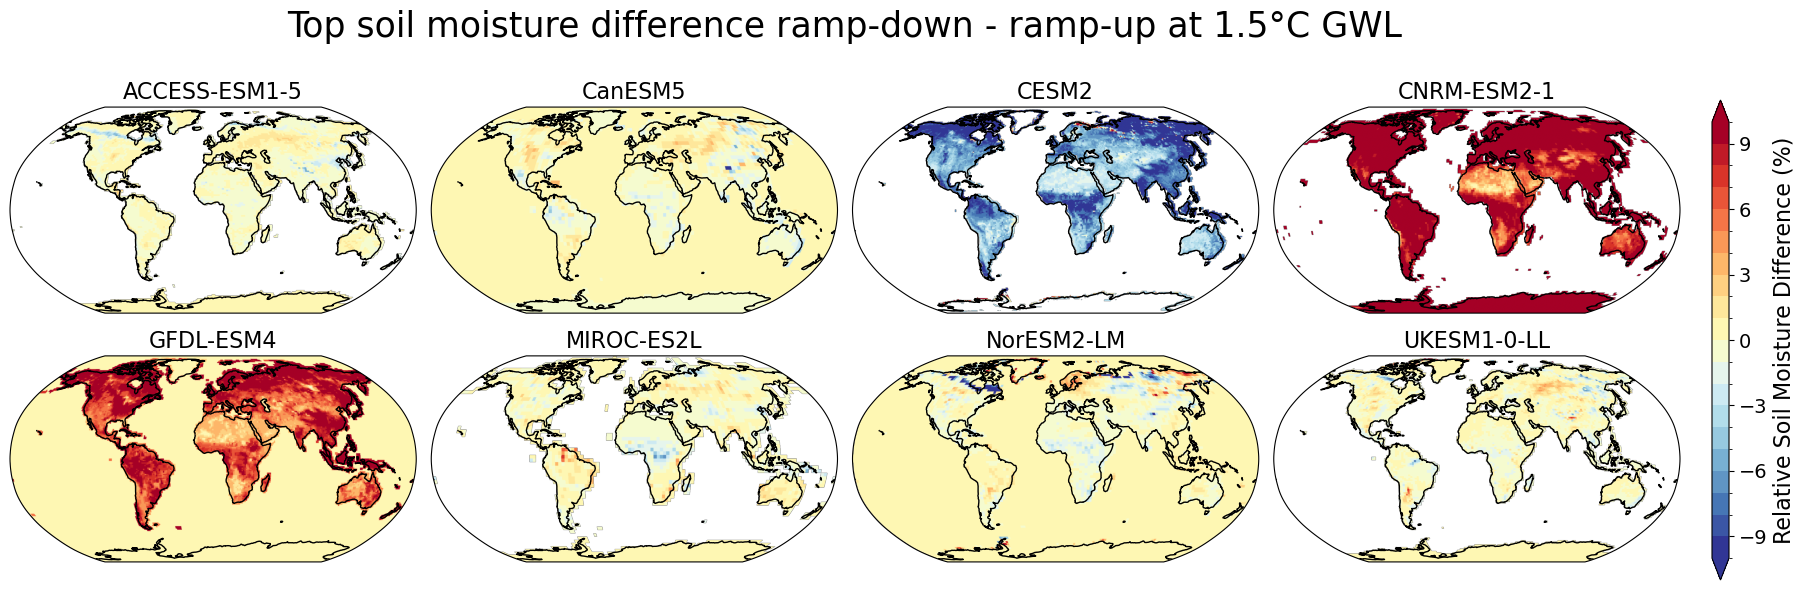

In [15]:
plot_gwl_diff(
    differences_15,
    np.linspace(-10,10,21)
)

### Save Data ###

In [ ]:
# save
save_dir = os.path.join(data_dir,'processed/mrsos')
for model, ds_dict in slices_15.items():
    for period, ds in ds_dict.items():
        path = os.path.join(
            save_dir,
            f"{model}_mrsos_{period}.nc"
        )
        # ds.to_netcdf(path)